In [1]:
import os, sys, json, time, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath("."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report, average_precision_score, roc_auc_score,
                             precision_recall_curve)
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTENC

from src.features import (extract_engineered_features, load_pipeline, load_data_and_split, time_of_day_band,
                          NUM_COLS, CAT_COLS, BIN_COLS, RAW_INPUT_COLS, CLASS_NAMES, RANDOM_STATE, MODELS_DIR)

pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
EVAL_DIR = os.path.join("reports", "evaluation"); FIG_DIR = os.path.join("reports", "figures")
os.makedirs(EVAL_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)

CLASS_COLORS = {"Fatal": "#2a78d6", "Serious": "#eb6834", "Slight": "#1baf7a"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 150, "font.size": 10, "axes.edgecolor": GRID,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.titlecolor": INK,
                     "axes.titleweight": "bold", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True})
def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name), bbox_inches="tight", facecolor="white")
print("ready")

ready


In [2]:
PRIMARY = "Macro F1"
GUARD_RAILS = {"Fatal Recall": 0.50, "Serious Recall": 0.30}
TIE_BAND, TIE_BREAK = 0.005, "Fatal PR-AUC"

def evaluate(y_true, y_pred, proba=None):
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1, 2], zero_division=0)
    out = {"Accuracy": accuracy_score(y_true, y_pred),
           "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
           "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
           "Weighted F1": f1_score(y_true, y_pred, average="weighted", zero_division=0)}
    for i, c in enumerate(CLASS_NAMES):
        out[f"{c} Precision"], out[f"{c} Recall"], out[f"{c} F1"] = p[i], r[i], f[i]
    if proba is not None:
        for i, c in enumerate(CLASS_NAMES):
            out[f"{c} PR-AUC"] = average_precision_score(y_true == i, proba[:, i])
        out["Macro ROC-AUC (OvR)"] = roc_auc_score(y_true, proba, multi_class="ovr", average="macro")
    return out

def select(table):
    ok = table[table["candidate"]].copy()
    for m, floor in GUARD_RAILS.items():
        ok = ok[ok[m] >= floor]
    if ok.empty:
        raise RuntimeError("No candidate meets the guard rails")
    best = ok[PRIMARY].max()
    near = ok[ok[PRIMARY] >= best - TIE_BAND]
    return near.sort_values(TIE_BREAK, ascending=False).index[0], ok.index.tolist()
print("metric definitions locked")

metric definitions locked


In [3]:
df, y, train_idx, test_idx = load_data_and_split()
df_train, df_test = df.loc[train_idx], df.loc[test_idx]
y_train, y_test = y.loc[train_idx], y.loc[test_idx]

inner_tr_idx, val_idx = train_test_split(train_idx, test_size=0.20, stratify=y_train, random_state=RANDOM_STATE)
df_itr, df_val = df.loc[inner_tr_idx], df.loc[val_idx]
y_itr, y_val = y.loc[inner_tr_idx], y.loc[val_idx]

holdout = pd.read_parquet(os.path.join(MODELS_DIR, "test_holdout_with_predictions.parquet"))
checks = {
    "train/test disjoint": len(set(train_idx) & set(test_idx)) == 0,
    "inner-train/val disjoint and inside train": len(set(inner_tr_idx) & set(val_idx)) == 0 and set(val_idx) <= set(train_idx),
    "test ids identical to Satyam's holdout (same order)": bool((df_test["collision_index"].values == holdout["collision_index"].values).all()),
}
saved = {"RF balanced (saved artifact)": load_pipeline(os.path.join(MODELS_DIR, "best_model_pipeline.joblib")),
         "XGB weighted (saved artifact)": load_pipeline(os.path.join(MODELS_DIR, "xgboost_pipeline.joblib"))}
saved_proba = {k: m.predict_proba(df_test) for k, m in saved.items()}
checks["saved RF reproduces stored predictions"] = bool((saved_proba["RF balanced (saved artifact)"].argmax(1) == holdout["pred_rf_idx"].values).all())
checks["saved XGB reproduces stored predictions"] = bool((saved_proba["XGB weighted (saved artifact)"].argmax(1) == holdout["pred_xgb_idx"].values).all())
display(pd.Series(checks, name="passed").to_frame())
assert all(checks.values())

split_tbl = pd.DataFrame({name: yy.map(dict(enumerate(CLASS_NAMES))).value_counts(normalize=True).reindex(CLASS_NAMES)
                          for name, yy in [("inner-train", y_itr), ("validation", y_val), ("train (full)", y_train), ("holdout test", y_test)]}).T
split_tbl["N"] = [len(y_itr), len(y_val), len(y_train), len(y_test)]
display(split_tbl.style.format({c: "{:.2%}" for c in CLASS_NAMES} | {"N": "{:,}"}))

,passed
train/test disjoint,True
inner-train/val disjoint and inside train,True
test ids identical to Satyam's holdout (same order),True
saved RF reproduces stored predictions,True
saved XGB reproduces stored predictions,True


collision_severity,Fatal,Serious,Slight,N
inner-train,1.47%,21.03%,77.50%,"332,793"
validation,1.47%,21.03%,77.50%,"83,199"
train (full),1.47%,21.03%,77.50%,"415,992"
holdout test,1.47%,21.03%,77.50%,"103,999"


In [4]:
used_raw = set(RAW_INPUT_COLS)
reasons = {
    "collision_severity": "TARGET", "collision_severity_label": "Target label (direct encoding)",
    "number_of_casualties": "Post-outcome: counted after injuries are known, strongly tied to severity",
    "collision_index": "Record ID", "date": "Raw string (month/weekend/hour derived instead)", "time": "Raw string",
    "date_parsed": "Raw datetime", "police_force": "Administrative reporting unit",
    "pedestrian_crossing": "Excluded by notebook 03 (operational)", "speed_limit_imputed": "Cleaning flag",
}
rows = []
for c in df.columns:
    if c in used_raw:
        status = "USED"
        note = {"number_of_vehicles": "Known at the scene; fine for report-time triage, NOT a pre-crash risk input",
                "latitude": "Location; risk of memorising local severity rates (ablated below)",
                "longitude": "Location; see latitude"}.get(c, "Pre-collision circumstance recorded at the scene")
    else:
        status = "excluded"
        note = reasons.get(c, "Not used by the pipeline (redundant code / label twin or not selected)")
    rows.append({"column": c, "status": status, "note": note})
inventory = pd.DataFrame(rows).sort_values(["status", "column"], ascending=[False, True])
inventory.to_csv(os.path.join(EVAL_DIR, "leakage_column_inventory.csv"), index=False)
display(inventory.reset_index(drop=True))

,column,status,note
0,carriageway_hazards,excluded,Not used by the pipeline (redundant code / lab...
1,carriageway_hazards_label,excluded,Not used by the pipeline (redundant code / lab...
2,collision_day,excluded,Not used by the pipeline (redundant code / lab...
3,collision_index,excluded,Record ID
4,collision_minute,excluded,Not used by the pipeline (redundant code / lab...
5,collision_month_name,excluded,Not used by the pipeline (redundant code / lab...
6,collision_severity,excluded,TARGET
7,collision_severity_label,excluded,Target label (direct encoding)
8,collision_year,excluded,Not used by the pipeline (redundant code / lab...
9,date,excluded,Raw string (month/weekend/hour derived instead)


In [5]:
probe_fields = {f: [f] for f in RAW_INPUT_COLS if f not in ("latitude", "longitude")}
probe_fields["latitude+longitude"] = ["latitude", "longitude"]
probe_fields.update({"number_of_casualties (EXCLUDED, positive control)": ["number_of_casualties"],
                     "police_force (EXCLUDED)": ["police_force"],
                     "special_conditions_at_site (unused)": ["special_conditions_at_site"],
                     "carriageway_hazards (unused)": ["carriageway_hazards"]})
probe_rows = []
for name, cols in probe_fields.items():
    cat = [c for c in cols if df[c].dtype == object or str(df[c].dtype) in ("string", "str") or c == "police_force"]
    num = [c for c in cols if c not in cat]
    pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat), ("num", "passthrough", num)])
    m = Pipeline([("pre", pre), ("dt", DecisionTreeClassifier(max_depth=6, min_samples_leaf=200, class_weight="balanced", random_state=RANDOM_STATE))])
    m.fit(df_itr[cols], y_itr)
    pr = m.predict_proba(df_val[cols])
    ev = evaluate(y_val, pr.argmax(1), pr)
    probe_rows.append({"field": name, "Macro F1": ev["Macro F1"], "Fatal Recall": ev["Fatal Recall"],
                       "Fatal PR-AUC": ev["Fatal PR-AUC"], "Macro ROC-AUC (OvR)": ev["Macro ROC-AUC (OvR)"]})
probe = pd.DataFrame(probe_rows).sort_values("Macro ROC-AUC (OvR)", ascending=False).reset_index(drop=True)
probe.to_csv(os.path.join(EVAL_DIR, "leakage_single_field_probe.csv"), index=False)
display(probe.style.format({c: "{:.3f}" for c in probe.columns if c != "field"}))

,field,Macro F1,Fatal Recall,Fatal PR-AUC,Macro ROC-AUC (OvR)
0,number_of_vehicles,0.258,0.633,0.022,0.589
1,latitude+longitude,0.257,0.663,0.026,0.586
2,speed_limit,0.271,0.635,0.029,0.577
3,police_force (EXCLUDED),0.208,0.842,0.020,0.560
4,urban_or_rural_area_label,0.268,0.624,0.023,0.555
5,junction_control_label,0.236,0.662,0.020,0.546
6,collision_hour,0.281,0.343,0.022,0.540
7,time_of_day_band,0.271,0.396,0.019,0.533
8,light_conditions_label,0.352,0.188,0.023,0.533
9,junction_detail_label,0.214,0.697,0.018,0.532


In [6]:
art_rows = []
for c in ["road_type_label", "weather_conditions_label", "road_surface_conditions_label", "light_conditions_label",
          "junction_detail_label", "junction_control_label"]:
    for lvl, g in df.groupby(c):
        if "unknown" in str(lvl).lower():
            art_rows.append({"field": c, "level": lvl, "N": len(g), "fatal rate": (g.collision_severity == 1).mean(),
                             "serious rate": (g.collision_severity == 2).mean()})
artifacts = pd.DataFrame(art_rows)
overall = (df.collision_severity == 1).mean()
print(f"Overall fatal rate: {overall:.2%}")
display(artifacts.style.format({"N": "{:,}", "fatal rate": "{:.2%}", "serious rate": "{:.2%}"}))

print("\nJunction label mapping check: raw junction_detail code vs label")
display(pd.crosstab(df["junction_detail"], df["junction_detail_label"]))

Overall fatal rate: 1.47%


,field,level,N,fatal rate,serious rate
0,road_type_label,Unknown,"12,686",0.18%,8.73%
1,weather_conditions_label,Missing / Unknown,13,23.08%,0.00%
2,weather_conditions_label,Unknown,"14,891",0.51%,11.97%
3,road_surface_conditions_label,Missing / Unknown,"2,803",0.39%,11.45%
4,road_surface_conditions_label,Unknown,"5,606",0.04%,7.30%
5,light_conditions_label,Darkness - lighting unknown,"10,154",1.52%,15.05%
6,light_conditions_label,Missing / Unknown,14,21.43%,7.14%
7,junction_detail_label,Missing / Unknown,"250,338",0.95%,20.12%
8,junction_control_label,Missing / Unknown,"228,777",2.17%,22.53%



Junction label mapping check: raw junction_detail code vs label


junction_detail_label,Missing / Unknown,Not at junction
junction_detail,,
-1,9183,0
0,0,269653
13,145652,0
16,48266,0
17,7542,0
18,11354,0
19,28341,0


In [7]:
key = ["date", "time", "latitude", "longitude"]
part = pd.Series("train", index=df.index); part.loc[test_idx] = "test"
d2 = df[key + ["collision_severity"]].assign(part=part)
d2["cluster"] = d2.groupby(key, sort=False).ngroup()
grp = d2.groupby("cluster").agg(n=("part", "size"), parts=("part", "nunique"), sev=("collision_severity", "nunique"))
straddle = grp[grp.parts > 1]
n_test_rows_in_straddle = int(((d2.part == "test") & d2.cluster.isin(straddle.index)).sum())
print(f"Incident clusters with members in both train and test: {len(straddle):,}")
print(f"Test rows involved: {n_test_rows_in_straddle:,} ({n_test_rows_in_straddle/len(test_idx):.2%} of holdout)")
print(f"Of those clusters, share where every record has the same severity: {(straddle.sev == 1).mean():.1%}")

Incident clusters with members in both train and test: 2
Test rows involved: 2 (0.00% of holdout)
Of those clusters, share where every record has the same severity: 100.0%


In [8]:
RF_PARAMS = dict(n_estimators=100, max_depth=12, min_samples_leaf=20, n_jobs=-1, random_state=RANDOM_STATE)
XGB_PARAMS = dict(n_estimators=100, max_depth=6, learning_rate=0.1, tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE)

def fe():
    return FunctionTransformer(extract_engineered_features)

def onehot_pre(num_cols=NUM_COLS):
    return ColumnTransformer([("num", StandardScaler(), num_cols),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
                              ("bin", "passthrough", BIN_COLS)])

n_num, n_cat = len(NUM_COLS), len(CAT_COLS)
cat_idx = list(range(n_num, n_num + n_cat)); bin_idx = list(range(n_num + n_cat, n_num + n_cat + len(BIN_COLS)))
def count_of(cls):
    return lambda yy: int(np.sum(np.asarray(yy) == cls))

def make(name):
    if name == "Dummy (majority)":
        return Pipeline([("fe", fe()), ("pre", onehot_pre()), ("clf", DummyClassifier(strategy="most_frequent"))])
    if name == "RF - none":
        return Pipeline([("fe", fe()), ("pre", onehot_pre()), ("clf", RandomForestClassifier(**RF_PARAMS))])
    if name == "RF - class weights":
        return Pipeline([("fe", fe()), ("pre", onehot_pre()), ("clf", RandomForestClassifier(class_weight="balanced_subsample", **RF_PARAMS))])
    if name == "RF - class weights, no coordinates (ablation)":
        nc = [c for c in NUM_COLS if c not in ("latitude", "longitude")]
        return Pipeline([("fe", fe()), ("pre", onehot_pre(nc)), ("clf", RandomForestClassifier(class_weight="balanced_subsample", **RF_PARAMS))])
    if name == "RF - random undersampling":
        return ImbPipeline([("fe", fe()), ("pre", onehot_pre()), ("rus", RandomUnderSampler(random_state=RANDOM_STATE)),
                            ("clf", RandomForestClassifier(**RF_PARAMS))])
    if name == "RF - hybrid SMOTENC":
        ord_pre = ColumnTransformer([("num", StandardScaler(), NUM_COLS),
                                     ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT_COLS),
                                     ("bin", "passthrough", BIN_COLS)])
        post = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_idx)], remainder="passthrough")
        return ImbPipeline([("fe", fe()), ("pre", ord_pre),
                            ("rus", RandomUnderSampler(sampling_strategy=lambda yy: {2: count_of(1)(yy)}, random_state=RANDOM_STATE)),
                            ("smotenc", SMOTENC(categorical_features=cat_idx + bin_idx, sampling_strategy=lambda yy: {0: count_of(1)(yy)}, random_state=RANDOM_STATE)),
                            ("post", post), ("clf", RandomForestClassifier(**RF_PARAMS))])
    if name in ("XGB - none", "XGB - sample weights"):
        return Pipeline([("fe", fe()), ("pre", onehot_pre()), ("clf", XGBClassifier(**XGB_PARAMS))])
    if name == "XGB - random undersampling":
        return ImbPipeline([("fe", fe()), ("pre", onehot_pre()), ("rus", RandomUnderSampler(random_state=RANDOM_STATE)),
                            ("clf", XGBClassifier(**XGB_PARAMS))])
    raise KeyError(name)

EXPERIMENTS = ["Dummy (majority)", "RF - none", "RF - class weights", "RF - random undersampling", "RF - hybrid SMOTENC",
               "XGB - none", "XGB - sample weights", "XGB - random undersampling",
               "RF - class weights, no coordinates (ablation)"]
NOT_CANDIDATES = {"Dummy (majority)", "RF - class weights, no coordinates (ablation)"}

def fit_eval(name, X_fit, y_fit, X_eval, y_eval):
    m = make(name)
    kw = {"clf__sample_weight": compute_sample_weight("balanced", y_fit)} if name == "XGB - sample weights" else {}
    t = time.time(); m.fit(X_fit, y_fit, **kw); fit_s = time.time() - t
    pr = m.predict_proba(X_eval)
    return m, pr, {**evaluate(y_eval, pr.argmax(1), pr), "Fit time (s)": fit_s}

val_rows, val_proba = {}, {}
for name in EXPERIMENTS:
    _, pr, ev = fit_eval(name, df_itr, y_itr, df_val, y_val)
    val_rows[name], val_proba[name] = ev, pr
    print(f"{name:<50s} macroF1={ev['Macro F1']:.4f}  fatalR={ev['Fatal Recall']:.3f}  seriousR={ev['Serious Recall']:.3f}  ({ev['Fit time (s)']:.0f}s)")
val_tbl = pd.DataFrame(val_rows).T
val_tbl["candidate"] = [n not in NOT_CANDIDATES for n in val_tbl.index]

Dummy (majority)                                   macroF1=0.2911  fatalR=0.000  seriousR=0.000  (2s)


RF - none                                          macroF1=0.2934  fatalR=0.000  seriousR=0.003  (13s)


RF - class weights                                 macroF1=0.3656  fatalR=0.564  seriousR=0.319  (13s)


RF - random undersampling                          macroF1=0.3390  fatalR=0.668  seriousR=0.242  (3s)


RF - hybrid SMOTENC                                macroF1=0.3724  fatalR=0.433  seriousR=0.382  (40s)


XGB - none                                         macroF1=0.3018  fatalR=0.000  seriousR=0.017  (9s)


XGB - sample weights                               macroF1=0.3565  fatalR=0.629  seriousR=0.327  (9s)


XGB - random undersampling                         macroF1=0.3402  fatalR=0.660  seriousR=0.293  (3s)


RF - class weights, no coordinates (ablation)      macroF1=0.3567  fatalR=0.592  seriousR=0.285  (13s)


In [9]:
SHOW = ["Accuracy", "Balanced Accuracy", "Macro F1", "Weighted F1", "Fatal Recall", "Serious Recall", "Slight Recall",
        "Fatal Precision", "Serious Precision", "Fatal PR-AUC", "Serious PR-AUC", "Macro ROC-AUC (OvR)", "Fit time (s)"]
chosen, eligible = select(val_tbl)
val_tbl["meets guard rails"] = val_tbl.index.isin(eligible)
val_tbl["selected"] = val_tbl.index == chosen
val_tbl.to_csv(os.path.join(EVAL_DIR, "imbalance_experiments_validation.csv"))
print(f"SELECTED (validation, by the rule fixed in section 1): {chosen}")
display(val_tbl[SHOW + ["meets guard rails", "selected"]].style.format({c: "{:.3f}" for c in SHOW}).format({"Fit time (s)": "{:.0f}"}))

SELECTED (validation, by the rule fixed in section 1): RF - class weights


,Accuracy,Balanced Accuracy,Macro F1,Weighted F1,Fatal Recall,Serious Recall,Slight Recall,Fatal Precision,Serious Precision,Fatal PR-AUC,Serious PR-AUC,Macro ROC-AUC (OvR),Fit time (s),meets guard rails,selected
Dummy (majority),0.774973,0.333333,0.291074,0.676724,0.000000,0.000000,1.000000,0.000000,0.000000,0.014700,0.210327,0.500000,2,False,False
RF - none,0.775057,0.334216,0.293384,0.678186,0.000000,0.003486,0.999162,0.000000,0.488000,0.059935,0.313467,0.694384,13,False,False
RF - class weights,0.559838,0.502835,0.365568,0.617720,0.564186,0.319275,0.625045,0.048064,0.268942,0.060484,0.245308,0.660022,13,True,True
RF - random undersampling,0.518840,0.500367,0.339017,0.591757,0.668029,0.241900,0.591172,0.037655,0.262740,0.059309,0.233518,0.651654,3,False,False
RF - hybrid SMOTENC,0.566810,0.478135,0.372398,0.620270,0.432543,0.382479,0.619384,0.048311,0.271841,0.052162,0.248742,0.652314,40,False,False
XGB - none,0.775334,0.337527,0.301815,0.683553,0.000000,0.016630,0.995952,0.000000,0.474715,0.068214,0.320173,0.705615,9,False,False
XGB - sample weights,0.529718,0.512988,0.356505,0.599645,0.628782,0.327447,0.582735,0.042521,0.274530,0.064221,0.254493,0.670618,9,True,False
XGB - random undersampling,0.505283,0.504158,0.340216,0.580170,0.659853,0.292531,0.560091,0.039707,0.255006,0.063636,0.238645,0.659895,3,False,False
"RF - class weights, no coordinates (ablation)",0.550463,0.499678,0.356715,0.611648,0.591987,0.285445,0.621602,0.043999,0.265734,0.059038,0.234980,0.651082,13,False,False


In [10]:
hold_rows, hold_proba, hold_models = {}, {}, {}
for name in EXPERIMENTS:
    m, pr, ev = fit_eval(name, df_train, y_train, df_test, y_test)
    hold_rows[name], hold_proba[name], hold_models[name] = ev, pr, m
for name, pr in saved_proba.items():
    hold_rows[name] = {**evaluate(y_test, pr.argmax(1), pr), "Fit time (s)": np.nan}; hold_proba[name] = pr
hold_tbl = pd.DataFrame(hold_rows).T
hold_tbl.to_csv(os.path.join(EVAL_DIR, "imbalance_experiments_holdout.csv"))
for a, b in [("RF - class weights", "RF balanced (saved artifact)"), ("XGB - sample weights", "XGB weighted (saved artifact)")]:
    agree = (hold_proba[a].argmax(1) == hold_proba[b].argmax(1)).mean()
    print(f"refit '{a}' vs '{b}': prediction agreement {agree:.4%}")
display(hold_tbl[SHOW].style.format({c: "{:.3f}" for c in SHOW}).format({"Fit time (s)": "{:.0f}"}, na_rep="(saved)"))

refit 'RF - class weights' vs 'RF balanced (saved artifact)': prediction agreement 98.3211%
refit 'XGB - sample weights' vs 'XGB weighted (saved artifact)': prediction agreement 95.5846%


,Accuracy,Balanced Accuracy,Macro F1,Weighted F1,Fatal Recall,Serious Recall,Slight Recall,Fatal Precision,Serious Precision,Fatal PR-AUC,Serious PR-AUC,Macro ROC-AUC (OvR),Fit time (s)
Dummy (majority),0.774969,0.333333,0.291073,0.676718,0.000000,0.000000,1.000000,0.000000,0.000000,0.014702,0.210329,0.500000,3
RF - none,0.775084,0.333994,0.292752,0.677795,0.000000,0.002514,0.999466,0.000000,0.523810,0.056838,0.309539,0.689596,19
RF - class weights,0.552063,0.499517,0.362447,0.612866,0.562459,0.321706,0.614385,0.045133,0.271458,0.055763,0.242782,0.655590,23
RF - random undersampling,0.523024,0.502901,0.342164,0.594101,0.663833,0.250571,0.594297,0.038748,0.266081,0.056013,0.232835,0.647111,3
RF - hybrid SMOTENC,0.563784,0.484054,0.371975,0.618554,0.455853,0.380817,0.615490,0.048092,0.274410,0.049486,0.247727,0.651471,45
XGB - none,0.775440,0.337489,0.301611,0.683429,0.000000,0.016275,0.996191,0.000000,0.490358,0.062440,0.317989,0.699909,12
XGB - sample weights,0.525274,0.514008,0.354552,0.596285,0.639634,0.324906,0.577485,0.042112,0.274232,0.059387,0.251832,0.666284,13
XGB - random undersampling,0.509370,0.503138,0.341204,0.582979,0.654676,0.288059,0.566678,0.039814,0.256493,0.056914,0.233757,0.654811,3
"RF - class weights, no coordinates (ablation)",0.547928,0.496294,0.356158,0.610267,0.582080,0.289339,0.617462,0.042389,0.269882,0.054654,0.233594,0.647488,21
RF balanced (saved artifact),0.552073,0.497302,0.362241,0.612928,0.555265,0.322255,0.614385,0.044609,0.271680,0.056298,0.242602,0.655533,(saved)


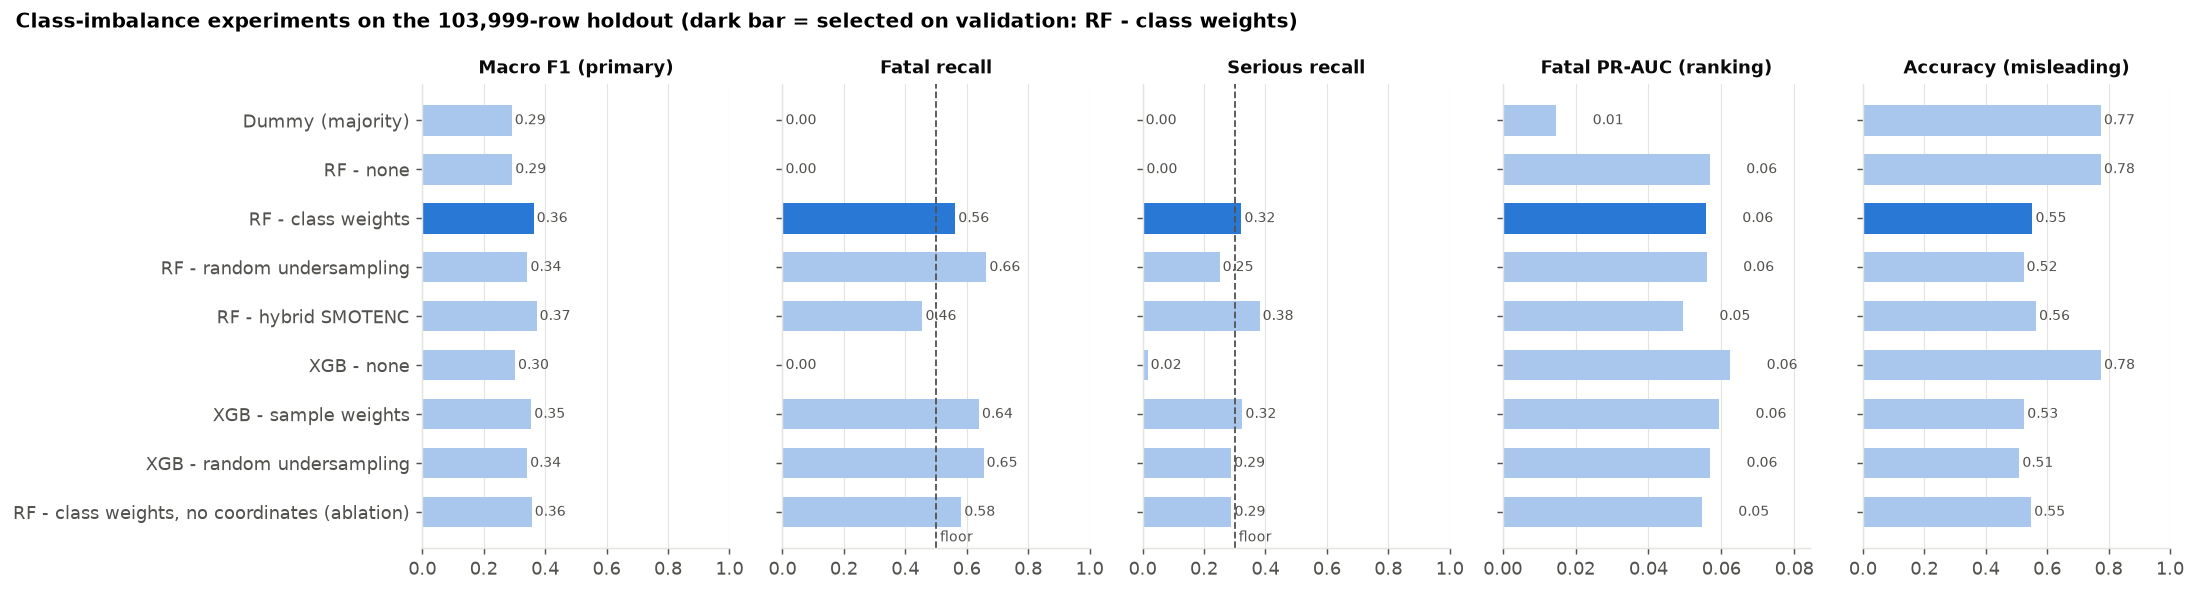

In [11]:
order = [n for n in EXPERIMENTS]
panels = [("Macro F1", "Macro F1 (primary)"), ("Fatal Recall", "Fatal recall"), ("Serious Recall", "Serious recall"),
          ("Fatal PR-AUC", "Fatal PR-AUC (ranking)"), ("Accuracy", "Accuracy (misleading)")]
fig, axes = plt.subplots(1, len(panels), figsize=(17, 4.6), sharey=True)
ypos = np.arange(len(order))
for ax, (col, title) in zip(axes, panels):
    vals = hold_tbl.loc[order, col].values
    colors = ["#2a78d6" if n == chosen else "#a9c6ec" for n in order]
    ax.barh(ypos, vals, color=colors, height=0.62)
    for yp, v in zip(ypos, vals):
        ax.text(v + 0.01, yp, f"{v:.2f}", va="center", fontsize=8, color=INK2)
    ax.set_title(title, fontsize=10); ax.set_xlim(0, max(1.0, vals.max() * 1.18) if col != "Fatal PR-AUC" else vals.max() * 1.35)
    ax.grid(axis="y", visible=False)
    if col in GUARD_RAILS:
        ax.axvline(GUARD_RAILS[col], color=INK2, lw=1, ls="--"); ax.text(GUARD_RAILS[col], len(order) - 0.4, " floor", fontsize=8, color=INK2)
axes[0].set_yticks(ypos); axes[0].set_yticklabels(order); axes[0].invert_yaxis()
fig.suptitle(f"Class-imbalance experiments on the 103,999-row holdout (dark bar = selected on validation: {chosen})", fontsize=11, fontweight="bold", x=0.01, ha="left")
plt.tight_layout(); savefig("fig12_imbalance_experiments_holdout.png"); plt.show()

In [12]:
SAVED_EQUIV = {"RF - class weights": ("RF balanced (saved artifact)", "best_model_pipeline.joblib"),
               "XGB - sample weights": ("XGB weighted (saved artifact)", "xgboost_pipeline.joblib")}
if chosen in SAVED_EQUIV:
    final_key, final_file = SAVED_EQUIV[chosen]
    final_model = saved[final_key]
    print(f"Selected config matches a saved artifact; evaluating models/{final_file}")
else:
    final_key, final_file = chosen, "selected_model_pipeline.joblib"
    final_model = hold_models[chosen]
    joblib.dump(final_model, os.path.join(MODELS_DIR, final_file))
    print(f"Selected config is new; saved refit pipeline to models/{final_file}")

proba = hold_proba[final_key]; pred = proba.argmax(1); yt = y_test.values
final_metrics = evaluate(yt, pred, proba)
print(classification_report(yt, pred, target_names=CLASS_NAMES, digits=3))
classwise = pd.DataFrame({c: {"Precision": final_metrics[f"{c} Precision"], "Recall": final_metrics[f"{c} Recall"],
                              "F1": final_metrics[f"{c} F1"], "PR-AUC": final_metrics[f"{c} PR-AUC"],
                              "Base rate (PR-AUC of random)": (yt == i).mean(), "Support": int((yt == i).sum())}
                          for i, c in enumerate(CLASS_NAMES)}).T
classwise.to_csv(os.path.join(EVAL_DIR, "final_classwise_metrics.csv"))
display(classwise.style.format("{:.3f}").format({"Support": "{:,.0f}"}))
summary = pd.Series({k: final_metrics[k] for k in ["Accuracy", "Balanced Accuracy", "Macro F1", "Weighted F1", "Macro ROC-AUC (OvR)"]})
display(summary.to_frame("holdout").style.format("{:.4f}"))

Selected config matches a saved artifact; evaluating models/best_model_pipeline.joblib


              precision    recall  f1-score   support

       Fatal      0.045     0.555     0.083      1529
     Serious      0.272     0.322     0.295     21874
      Slight      0.839     0.614     0.709     80596

    accuracy                          0.552    103999
   macro avg      0.385     0.497     0.362    103999
weighted avg      0.708     0.552     0.613    103999



,Precision,Recall,F1,PR-AUC,Base rate (PR-AUC of random),Support
Fatal,0.044609,0.555265,0.082584,0.056298,0.014702,"1,529"
Serious,0.271680,0.322255,0.294814,0.242602,0.210329,"21,874"
Slight,0.838973,0.614385,0.709326,0.852489,0.774969,"80,596"


,holdout
Accuracy,0.5521
Balanced Accuracy,0.4973
Macro F1,0.3622
Weighted F1,0.6129
Macro ROC-AUC (OvR),0.6555


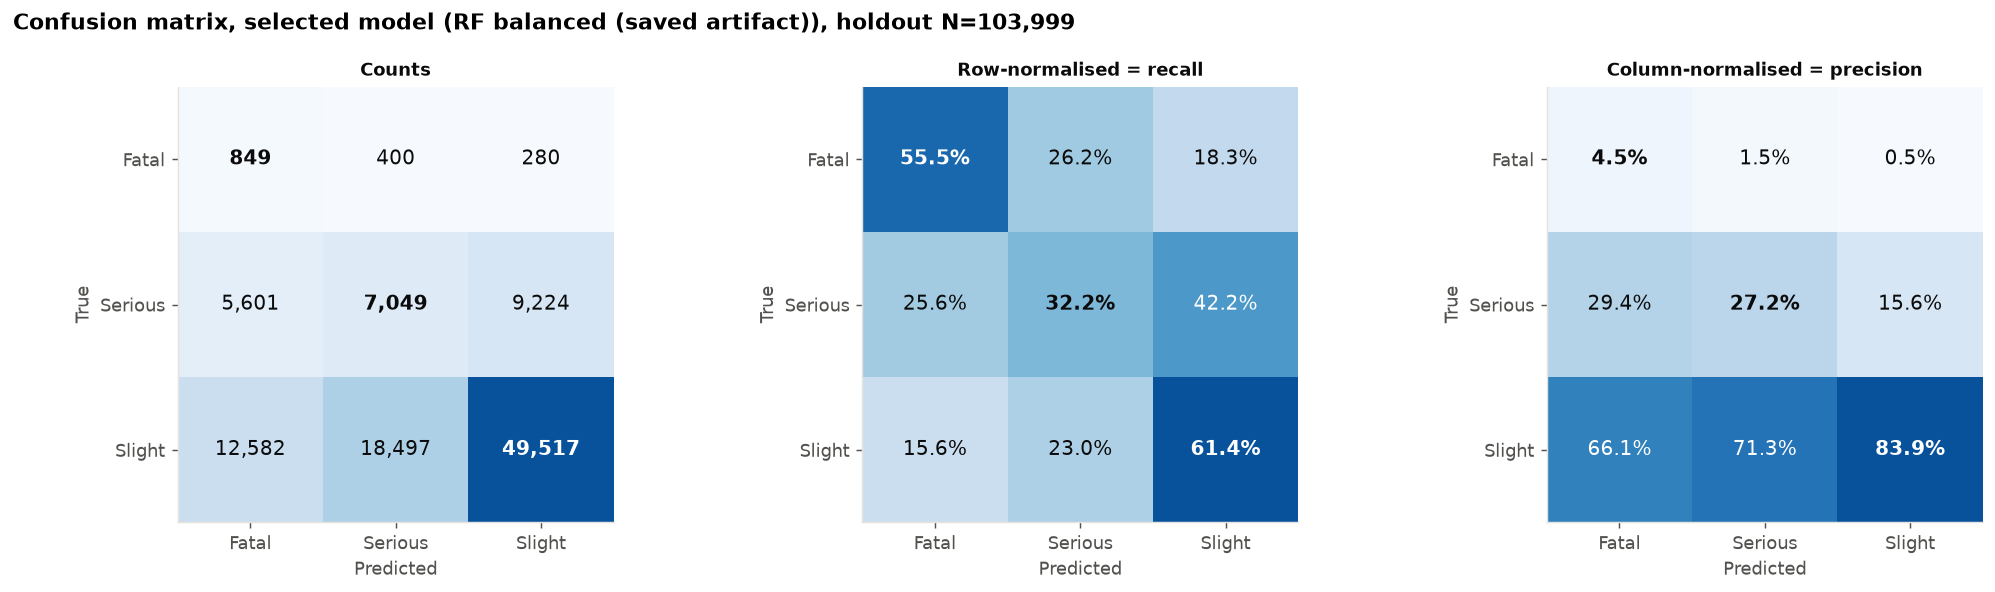

In [13]:
cm = confusion_matrix(yt, pred, labels=[0, 1, 2])
pd.DataFrame(cm, index=[f"true {c}" for c in CLASS_NAMES], columns=[f"pred {c}" for c in CLASS_NAMES]).to_csv(os.path.join(EVAL_DIR, "final_confusion_matrix.csv"))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
views = [(cm, "Counts", "{:,.0f}"), (cm / cm.sum(1, keepdims=True), "Row-normalised = recall", "{:.1%}"),
         (cm / cm.sum(0, keepdims=True), "Column-normalised = precision", "{:.1%}")]
for ax, (mat, title, fmt) in zip(axes, views):
    norm = mat / mat.max()
    ax.imshow(norm, cmap="Blues", vmin=0, vmax=1.15)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, fmt.format(mat[i, j]), ha="center", va="center", fontsize=11,
                    color="white" if norm[i, j] > 0.55 else INK, fontweight="bold" if i == j else "normal")
    ax.set_xticks(range(3)); ax.set_xticklabels(CLASS_NAMES); ax.set_yticks(range(3)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title, fontsize=10); ax.grid(False)
fig.suptitle(f"Confusion matrix, selected model ({final_key}), holdout N={len(yt):,}", fontweight="bold", x=0.01, ha="left")
plt.tight_layout(); savefig("fig13_confusion_matrix_selected_model.png"); plt.show()

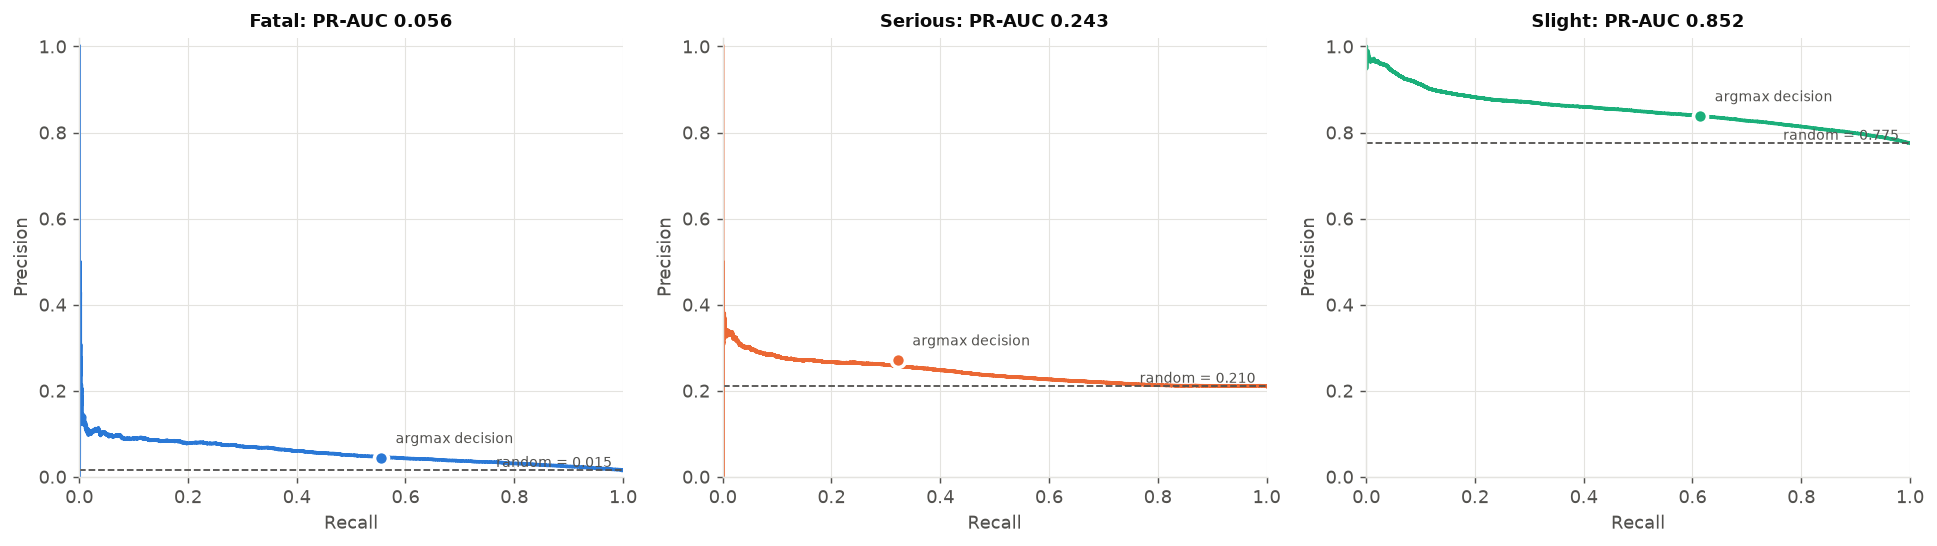

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for i, (ax, c) in enumerate(zip(axes, CLASS_NAMES)):
    pr_, rc_, _ = precision_recall_curve(yt == i, proba[:, i])
    base = (yt == i).mean()
    ax.plot(rc_, pr_, color=CLASS_COLORS[c], lw=2)
    ax.axhline(base, color=INK2, ls="--", lw=1); ax.text(0.98, base, f"random = {base:.3f}", ha="right", va="bottom", fontsize=8, color=INK2)
    i_pt = final_metrics[f"{c} Recall"], final_metrics[f"{c} Precision"]
    ax.scatter(*i_pt, s=60, color=CLASS_COLORS[c], edgecolor="white", linewidth=2, zorder=3)
    ax.annotate("argmax decision", i_pt, xytext=(8, 8), textcoords="offset points", fontsize=8, color=INK2)
    ax.set_title(f"{c}: PR-AUC {final_metrics[f'{c} PR-AUC']:.3f}", fontsize=10)
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
plt.tight_layout(); savefig("fig14_precision_recall_curves.png"); plt.show()

In [15]:
order_idx = np.argsort(-proba[:, 0]); base = (yt == 0).mean(); rows = []
for k in [0.005, 0.01, 0.02, 0.05, 0.10, 0.20, 0.30]:
    top = order_idx[: int(round(k * len(yt)))]
    hits = (yt[top] == 0)
    rows.append({"top % by fatal score": f"{k:.1%}", "collisions flagged": len(top), "fatal captured": int(hits.sum()),
                 "precision": hits.mean(), "share of all fatals (recall)": hits.sum() / (yt == 0).sum(), "lift vs base rate": hits.mean() / base})
lift = pd.DataFrame(rows); lift.to_csv(os.path.join(EVAL_DIR, "final_fatal_lift_table.csv"), index=False)
print(f"Fatal base rate in holdout: {base:.2%}")
display(lift.style.format({"precision": "{:.2%}", "share of all fatals (recall)": "{:.1%}", "lift vs base rate": "{:.1f}x", "collisions flagged": "{:,}"}))

calib = pd.DataFrame({"mean predicted probability": proba.mean(0), "observed rate": [(yt == i).mean() for i in range(3)],
                      "Brier (one-vs-rest)": [np.mean((proba[:, i] - (yt == i)) ** 2) for i in range(3)]}, index=CLASS_NAMES)
calib["inflation factor"] = calib["mean predicted probability"] / calib["observed rate"]
calib.to_csv(os.path.join(EVAL_DIR, "final_probability_calibration.csv"))
display(calib.style.format("{:.4f}").format({"inflation factor": "{:.1f}x"}))

Fatal base rate in holdout: 1.47%


,top % by fatal score,collisions flagged,fatal captured,precision,share of all fatals (recall),lift vs base rate
0,0.5%,520,56,10.77%,3.7%,7.3x
1,1.0%,"1,040",98,9.42%,6.4%,6.4x
2,2.0%,"2,080",185,8.89%,12.1%,6.0x
3,5.0%,"5,200",396,7.62%,25.9%,5.2x
4,10.0%,"10,400",623,5.99%,40.7%,4.1x
5,20.0%,"20,800",903,4.34%,59.1%,3.0x
6,30.0%,"31,200",1106,3.54%,72.3%,2.4x


,mean predicted probability,observed rate,Brier (one-vs-rest),inflation factor
Fatal,0.224388,0.014702,0.076755,15.3x
Serious,0.361639,0.210329,0.189759,1.7x
Slight,0.413973,0.774969,0.300446,0.5x


In [16]:
pairs = []
for i, t in enumerate(CLASS_NAMES):
    for j, p in enumerate(CLASS_NAMES):
        if i != j:
            pairs.append({"true": t, "predicted": p, "count": cm[i, j], "% of true class": cm[i, j] / cm[i].sum(),
                          "% of that prediction": cm[i, j] / cm[:, j].sum()})
pairs = pd.DataFrame(pairs).sort_values("count", ascending=False).reset_index(drop=True)
pairs.to_csv(os.path.join(EVAL_DIR, "error_confusion_pairs.csv"), index=False)
display(pairs.style.format({"count": "{:,}", "% of true class": "{:.1%}", "% of that prediction": "{:.1%}"}))

,true,predicted,count,% of true class,% of that prediction
0,Slight,Serious,"18,497",23.0%,71.3%
1,Slight,Fatal,"12,582",15.6%,66.1%
2,Serious,Slight,"9,224",42.2%,15.6%
3,Serious,Fatal,"5,601",25.6%,29.4%
4,Fatal,Serious,400,26.2%,1.5%
5,Fatal,Slight,280,18.3%,0.5%


In [17]:
ev_df = df_test.assign(true=yt, pred=pred, p_fatal=proba[:, 0], p_serious=proba[:, 1], p_slight=proba[:, 2])
ev_df["vehicles"] = pd.cut(ev_df.number_of_vehicles, [0, 1, 2, 99], labels=["1 (single)", "2", "3+"])
ev_df["speed"] = ev_df.speed_limit.astype(int).astype(str) + " mph"

def seg(g):
    return pd.Series({"N": len(g), "fatal share": (g.true == 0).mean(),
                      "accuracy": accuracy_score(g.true, g.pred), "macro F1": f1_score(g.true, g.pred, average="macro", labels=[0, 1, 2], zero_division=0),
                      "fatal recall": ((g.true == 0) & (g.pred == 0)).sum() / max((g.true == 0).sum(), 1),
                      "serious recall": ((g.true == 1) & (g.pred == 1)).sum() / max((g.true == 1).sum(), 1),
                      "fatal precision": ((g.true == 0) & (g.pred == 0)).sum() / max((g.pred == 0).sum(), 1),
                      "% predicted Fatal": (g.pred == 0).mean()})
seg_tbls = []
for col in ["urban_or_rural_area_label", "speed", "vehicles", "light_conditions_label", "time_of_day_band", "road_surface_conditions_label"]:
    t = ev_df.groupby(col, observed=True).apply(seg)
    t = t[t.N >= 500]
    t.index = pd.MultiIndex.from_product([[col], t.index])
    seg_tbls.append(t)
segments = pd.concat(seg_tbls)
segments.to_csv(os.path.join(EVAL_DIR, "error_segments.csv"))
display(segments.style.format("{:.3f}").format({"N": "{:,.0f}", "fatal share": "{:.2%}", "% predicted Fatal": "{:.1%}"}))

In [18]:
fat = ev_df[ev_df.true == 0]
def profile(g):
    return pd.Series({"N": len(g), "mean speed limit": g.speed_limit.mean(), "% rural": (g.urban_or_rural_area_label == "Rural").mean(),
                      "% single vehicle": (g.number_of_vehicles == 1).mean(), "% daylight": (g.light_conditions_label == "Daylight").mean(),
                      "% night (19-07h)": g.time_of_day_band.str.startswith("Night").mean(), "% unlit dark": g.light_conditions_label.isin(["Darkness - no lighting", "Darkness - lights unlit"]).mean(),
                      "% 30 mph or less": (g.speed_limit <= 30).mean(), "median p_fatal": g.p_fatal.median()})
fatal_profile = pd.DataFrame({"caught (pred Fatal)": profile(fat[fat.pred == 0]),
                              "missed -> pred Serious": profile(fat[fat.pred == 1]),
                              "missed -> pred Slight": profile(fat[fat.pred == 2]),
                              "ALL non-fatal (reference)": profile(ev_df[ev_df.true != 0])}).T
fatal_profile.to_csv(os.path.join(EVAL_DIR, "error_fatal_caught_vs_missed_profile.csv"))
display(fatal_profile.style.format("{:.1%}").format({"N": "{:,.0f}", "mean speed limit": "{:.1f}", "median p_fatal": "{:.3f}"}))

,N,mean speed limit,% rural,% single vehicle,% daylight,% night (19-07h),% unlit dark,% 30 mph or less,median p_fatal
caught (pred Fatal),849,56.4,0.855124,0.453475,0.531213,0.473498,0.285041,0.091873,0.532
missed -> pred Serious,400,34.8,0.355000,0.777500,0.617500,0.337500,0.085000,0.705000,0.292
missed -> pred Slight,280,35.6,0.210714,0.017857,0.678571,0.289286,0.007143,0.717857,0.163
ALL non-fatal (reference),"102,470",36.1,0.320338,0.286318,0.717429,0.249117,0.057295,0.698780,0.179


In [19]:
SHOW_COLS = ["collision_index", "speed_limit", "urban_or_rural_area_label", "number_of_vehicles", "road_type_label",
             "light_conditions_label", "weather_conditions_label", "collision_hour", "junction_detail_label", "p_fatal", "p_serious", "p_slight"]
lab = dict(enumerate(CLASS_NAMES))
kinds = [("Missed fatal: true Fatal, predicted Slight", (ev_df.true == 0) & (ev_df.pred == 2), "p_slight"),
         ("False fatal alarm: true Slight, predicted Fatal", (ev_df.true == 2) & (ev_df.pred == 0), "p_fatal"),
         ("Missed serious: true Serious, predicted Slight", (ev_df.true == 1) & (ev_df.pred == 2), "p_slight"),
         ("Over-escalated: true Slight, predicted Serious", (ev_df.true == 2) & (ev_df.pred == 1), "p_serious")]
reps = []
for kind, mask, conf in kinds:
    r = ev_df[mask].sort_values(conf, ascending=False).head(4)[SHOW_COLS].assign(error_type=kind)
    reps.append(r)
reps = pd.concat(reps)[["error_type"] + SHOW_COLS].reset_index(drop=True)
reps.to_csv(os.path.join(EVAL_DIR, "error_representative_examples.csv"), index=False)
display(reps.style.format({"p_fatal": "{:.3f}", "p_serious": "{:.3f}", "p_slight": "{:.3f}", "speed_limit": "{:.0f}"}))

,error_type,collision_index,speed_limit,urban_or_rural_area_label,number_of_vehicles,road_type_label,light_conditions_label,weather_conditions_label,collision_hour,junction_detail_label,p_fatal,p_serious,p_slight
0,"Missed fatal: true Fatal, predicted Slight",2022010400031,30,Urban,2,Roundabout,Daylight,Fine no high winds,13,Not at junction,0.051,0.328,0.621
1,"Missed fatal: true Fatal, predicted Slight",2023010466120,30,Urban,2,Roundabout,Daylight,Fine no high winds,8,Not at junction,0.042,0.339,0.618
2,"Missed fatal: true Fatal, predicted Slight",2023010444763,20,Urban,2,One way street,Daylight,Fine no high winds,7,Missing / Unknown,0.030,0.359,0.610
3,"Missed fatal: true Fatal, predicted Slight",2019430332799,30,Urban,2,Roundabout,Darkness - lights lit,Fine no high winds,18,Not at junction,0.058,0.334,0.608
4,"False fatal alarm: true Slight, predicted Fatal",2021101110766,60,Rural,2,Single carriageway,Darkness - no lighting,Fine no high winds,3,Not at junction,0.805,0.131,0.064
5,"False fatal alarm: true Slight, predicted Fatal",201931B046119,60,Rural,2,Single carriageway,Darkness - no lighting,Fine no high winds,1,Not at junction,0.787,0.144,0.069
6,"False fatal alarm: true Slight, predicted Fatal",2019940004519,60,Rural,2,Single carriageway,Darkness - no lighting,Fine no high winds,1,Not at junction,0.785,0.144,0.071
7,"False fatal alarm: true Slight, predicted Fatal",2023991451985,70,Urban,2,Dual carriageway,Darkness - no lighting,Fine no high winds,1,Not at junction,0.782,0.121,0.098
8,"Missed serious: true Serious, predicted Slight",2021010347289,20,Urban,2,Unknown,Daylight,Unknown,15,Missing / Unknown,0.003,0.108,0.889
9,"Missed serious: true Serious, predicted Slight",2023010479217,20,Urban,2,Unknown,Daylight,Unknown,13,Missing / Unknown,0.005,0.111,0.885


In [20]:
clf = final_model.steps[-1][1]
transform_part = final_model[:-1]
feat_names = None
for _, step in reversed(final_model.steps[:-1]):
    if isinstance(step, ColumnTransformer):
        try:
            feat_names = list(step.get_feature_names_out())
        except Exception:
            pass
        break
if feat_names is None or len(feat_names) != clf.n_features_in_:
    feat_names = [f"f{i}" for i in range(clf.n_features_in_)]
clean = [n.split("__", 1)[-1] for n in feat_names]

def raw_group(n):
    for c in CAT_COLS:
        if n.startswith(c + "_") or n == c:
            return c
    return n
if hasattr(clf, "feature_importances_"):
    gini = pd.DataFrame({"feature": clean, "importance": clf.feature_importances_}).sort_values("importance", ascending=False)
    gini_grouped = gini.assign(group=gini.feature.map(raw_group)).groupby("group").importance.sum().sort_values(ascending=False)
    gini_grouped.to_csv(os.path.join(EVAL_DIR, "importance_gini_grouped.csv"))
    display(gini_grouped.head(15).to_frame("Gini importance (one-hot summed)"))

,Gini importance (one-hot summed)
group,
speed_limit,0.108853
latitude,0.083863
longitude,0.077860
kinetic_energy_proxy,0.076661
speed_x_rural,0.066773
number_of_vehicles,0.065403
single_vehicle_crash,0.053394
urban_or_rural_area_label,0.051756
light_conditions_label,0.043650


baseline on sample: macro F1 0.3678, Fatal PR-AUC 0.0603


,input field,drop in macro F1,sd (F1),drop in Fatal PR-AUC,sd (AP)
0,number_of_vehicles,0.0317,0.0011,0.0124,0.0006
1,location (lat+lon),0.0032,0.0003,0.0087,0.0018
2,first_road_class_label,0.0027,0.0001,0.0114,0.0025
3,road_type_label,0.0024,0.0016,0.0048,0.0018
4,weather_conditions_label,0.0016,0.0004,0.0027,0.0010
5,hour (+ time_of_day_band),0.0007,0.0014,0.0092,0.0017
6,road_surface_conditions_label,0.0002,0.0007,0.0015,0.0004
7,is_weekend,0.0001,0.0004,0.0012,0.0011
8,collision_month,-0.0009,0.0005,0.0009,0.0008
9,junction_detail_label,-0.0035,0.0010,0.0022,0.0027


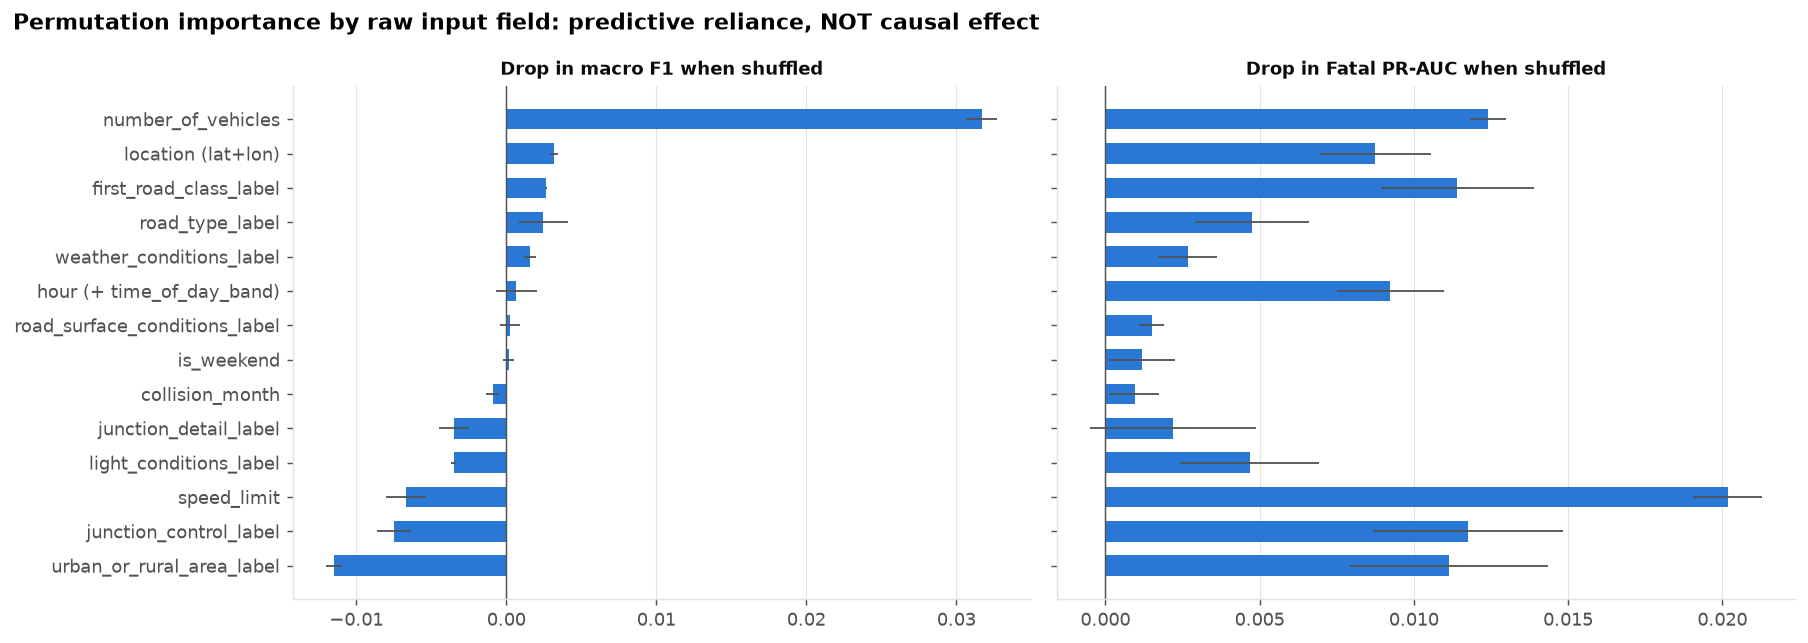

In [21]:
rng = np.random.default_rng(RANDOM_STATE)
samp_idx, _ = train_test_split(test_idx, train_size=20000, stratify=y_test, random_state=RANDOM_STATE)
Xs, ys = df.loc[samp_idx].copy(), y.loc[samp_idx].values
groups = {"speed_limit": ["speed_limit"], "number_of_vehicles": ["number_of_vehicles"],
          "location (lat+lon)": ["latitude", "longitude"], "hour (+ time_of_day_band)": ["collision_hour", "time_of_day_band"],
          "collision_month": ["collision_month"], "is_weekend": ["is_weekend"]}
groups.update({c: [c] for c in CAT_COLS if c != "time_of_day_band"})
def scores(X):
    p = final_model.predict_proba(X)
    return f1_score(ys, p.argmax(1), average="macro"), average_precision_score(ys == 0, p[:, 0])
base_f1, base_ap = scores(Xs)
perm_rows = []
for gname, cols in groups.items():
    d_f1, d_ap = [], []
    for rep in range(3):
        Xp = Xs.copy(); perm = rng.permutation(len(Xp))
        for c in cols:
            Xp[c] = Xs[c].values[perm]
        f1p, app = scores(Xp); d_f1.append(base_f1 - f1p); d_ap.append(base_ap - app)
    perm_rows.append({"input field": gname, "drop in macro F1": np.mean(d_f1), "sd (F1)": np.std(d_f1),
                      "drop in Fatal PR-AUC": np.mean(d_ap), "sd (AP)": np.std(d_ap)})
perm = pd.DataFrame(perm_rows).sort_values("drop in macro F1", ascending=False).reset_index(drop=True)
perm.to_csv(os.path.join(EVAL_DIR, "importance_permutation_raw_fields.csv"), index=False)
print(f"baseline on sample: macro F1 {base_f1:.4f}, Fatal PR-AUC {base_ap:.4f}")
display(perm.style.format({c: "{:.4f}" for c in perm.columns if c != "input field"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
yp = np.arange(len(perm))
for ax, (col, sd, title, color) in zip(axes, [("drop in macro F1", "sd (F1)", "Drop in macro F1 when shuffled", "#2a78d6"),
                                               ("drop in Fatal PR-AUC", "sd (AP)", "Drop in Fatal PR-AUC when shuffled", CLASS_COLORS["Fatal"])]):
    ax.barh(yp, perm[col], xerr=perm[sd], color=color, height=0.6, error_kw={"ecolor": INK2, "lw": 1})
    ax.axvline(0, color=INK2, lw=0.8); ax.set_title(title, fontsize=10); ax.grid(axis="y", visible=False)
axes[0].set_yticks(yp); axes[0].set_yticklabels(perm["input field"]); axes[0].invert_yaxis()
fig.suptitle("Permutation importance by raw input field: predictive reliance, NOT causal effect", fontweight="bold", x=0.01, ha="left")
plt.tight_layout(); savefig("fig15_permutation_importance_raw_fields.png"); plt.show()

SHAP values loaded from cache reports\evaluation\shap_cache_best_model_pipeline.npz (delete it to recompute)


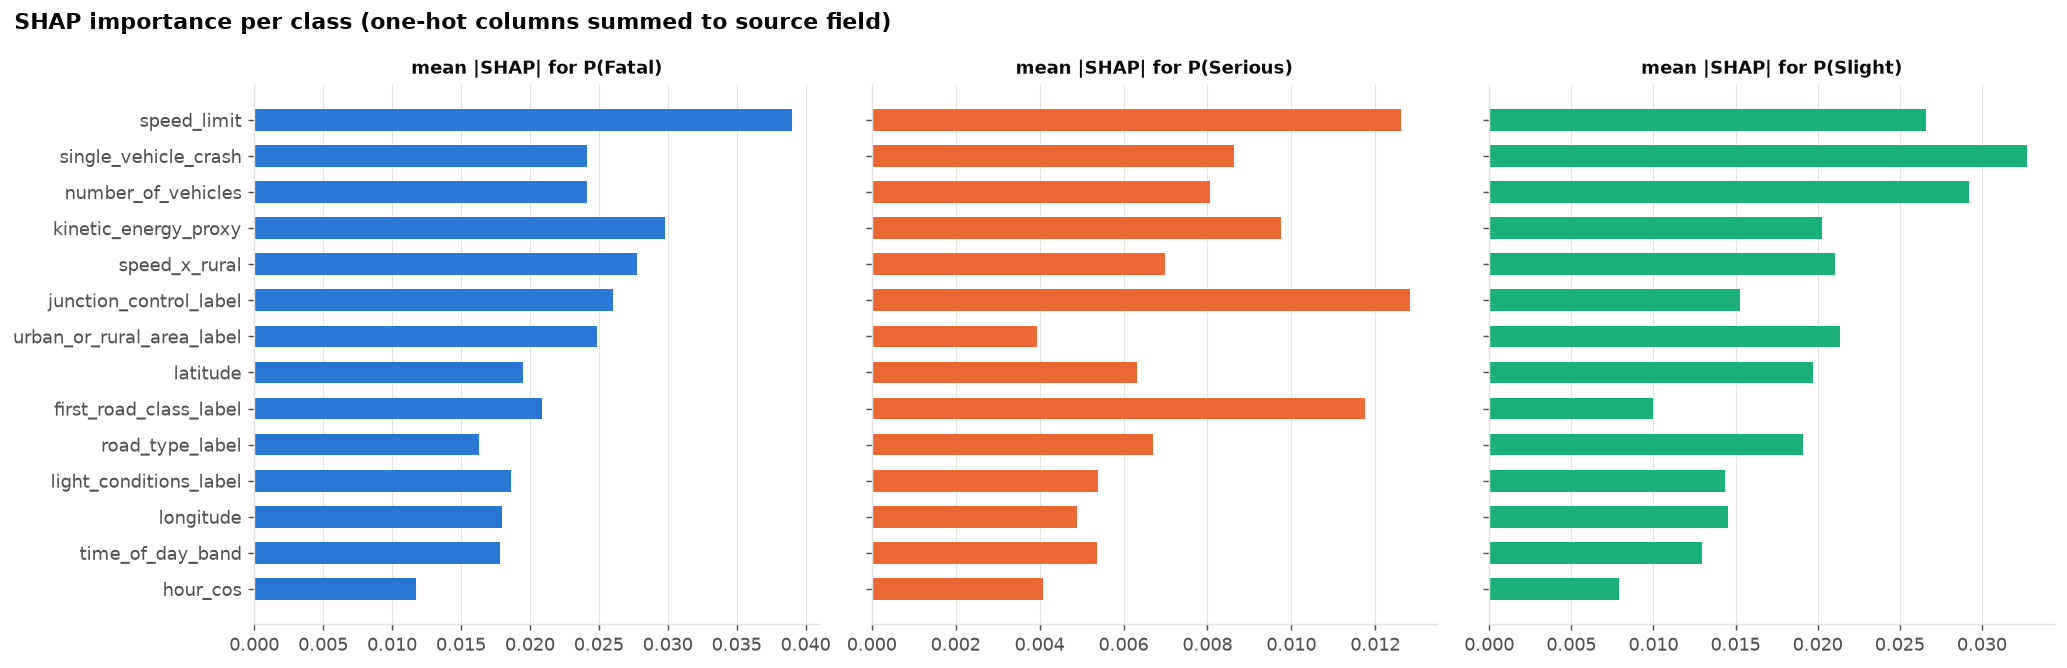

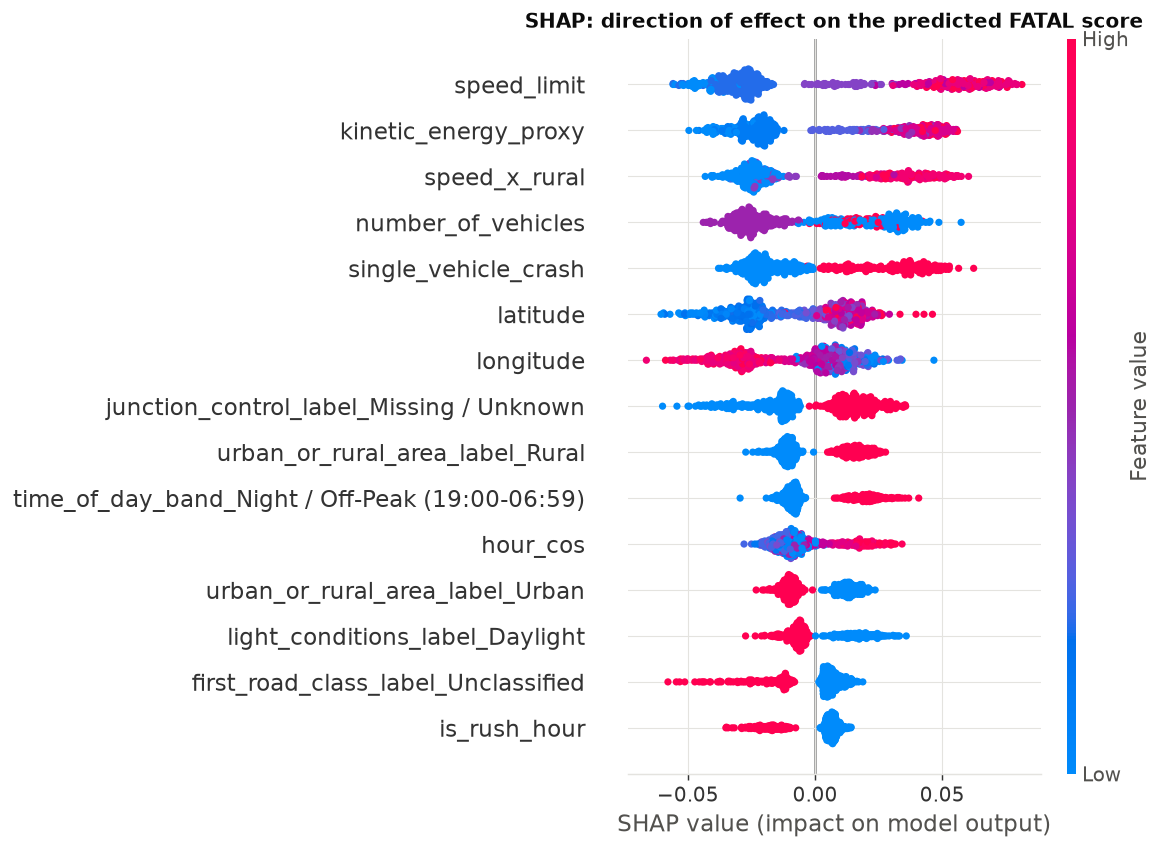

In [22]:
SHAP_OK = False
try:
    import shap
    shap_idx = np.concatenate([rng.choice(np.where(y_test.values == k)[0], 200, replace=False) for k in range(3)])
    X_shap_raw = df_test.iloc[shap_idx]
    X_shap = transform_part.transform(X_shap_raw)
    cache = os.path.join(EVAL_DIR, f"shap_cache_{final_file.replace('.joblib', '')}.npz")
    ids = X_shap_raw["collision_index"].astype(str).values
    if os.path.exists(cache) and np.array_equal(np.load(cache, allow_pickle=True)["ids"], ids):
        sv = np.load(cache, allow_pickle=True)["sv"]
        print(f"SHAP values loaded from cache {cache} (delete it to recompute)")
    else:
        t = time.time()
        explainer = shap.TreeExplainer(clf)
        sv = explainer.shap_values(X_shap, check_additivity=False)
        sv = np.stack(sv, axis=-1) if isinstance(sv, list) else np.asarray(sv)
        np.savez_compressed(cache, sv=sv, ids=ids)
        print(f"SHAP computed in {time.time() - t:.0f}s, shape {sv.shape}")
    SHAP_OK = True
except Exception as e:
    print("SHAP not available:", type(e).__name__, e)

if SHAP_OK:
    grp = pd.Series([raw_group(n) for n in clean])
    mean_abs = pd.DataFrame({c: pd.Series(np.abs(sv[:, :, i]).mean(0)).groupby(grp.values).sum() for i, c in enumerate(CLASS_NAMES)})
    mean_abs = mean_abs.loc[mean_abs.sum(1).sort_values(ascending=False).index]
    mean_abs.to_csv(os.path.join(EVAL_DIR, "importance_shap_mean_abs_grouped.csv"))
    top = mean_abs.head(14)
    fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), sharey=True)
    yp = np.arange(len(top))
    for ax, c in zip(axes, CLASS_NAMES):
        ax.barh(yp, top[c], color=CLASS_COLORS[c], height=0.6); ax.set_title(f"mean |SHAP| for P({c})", fontsize=10)
        ax.grid(axis="y", visible=False)
    axes[0].set_yticks(yp); axes[0].set_yticklabels(top.index); axes[0].invert_yaxis()
    fig.suptitle("SHAP importance per class (one-hot columns summed to source field)", fontweight="bold", x=0.01, ha="left")
    plt.tight_layout(); savefig("fig16_shap_importance_per_class.png"); plt.show()

    plt.figure()
    shap.summary_plot(sv[:, :, 0], X_shap, feature_names=clean, max_display=15, show=False, plot_size=(9, 6.5))
    plt.title("SHAP: direction of effect on the predicted FATAL score", fontsize=11, fontweight="bold")
    savefig("fig17_shap_beeswarm_fatal.png"); plt.show()

In [23]:
summary_out = {
    "evaluated_on": f"stratified 20% holdout (random_state=42), N={len(yt)}; identical rows to models/test_holdout_with_predictions.parquet",
    "selection_rule": {"primary": PRIMARY, "guard_rails": GUARD_RAILS, "tie_break": TIE_BREAK, "tie_band": TIE_BAND,
                       "selection_data": "validation split (20% of training rows), never the holdout"},
    "selected_config": chosen, "selected_model_file": f"models/{final_file}",
    "validation_ranking": val_tbl.loc[val_tbl.candidate].sort_values(PRIMARY, ascending=False)[[PRIMARY, "Fatal Recall", "Serious Recall", "Fatal PR-AUC"]].round(4).to_dict(orient="index"),
    "holdout_metrics": {k: round(float(v), 4) for k, v in final_metrics.items()},
    "fatal_lift_top_5pct": float(lift.loc[lift["top % by fatal score"] == "5.0%", "lift vs base rate"].iloc[0]),
    "class_names": CLASS_NAMES,
}
with open(os.path.join(MODELS_DIR, "evaluation_summary.json"), "w") as f:
    json.dump(summary_out, f, indent=2)
print(json.dumps(summary_out, indent=2))

{
  "evaluated_on": "stratified 20% holdout (random_state=42), N=103999; identical rows to models/test_holdout_with_predictions.parquet",
  "selection_rule": {
    "primary": "Macro F1",
    "guard_rails": {
      "Fatal Recall": 0.5,
      "Serious Recall": 0.3
    },
    "tie_break": "Fatal PR-AUC",
    "tie_band": 0.005,
    "selection_data": "validation split (20% of training rows), never the holdout"
  },
  "selected_config": "RF - class weights",
  "selected_model_file": "models/best_model_pipeline.joblib",
  "validation_ranking": {
    "RF - hybrid SMOTENC": {
      "Macro F1": 0.3724,
      "Fatal Recall": 0.4325,
      "Serious Recall": 0.3825,
      "Fatal PR-AUC": 0.0522
    },
    "RF - class weights": {
      "Macro F1": 0.3656,
      "Fatal Recall": 0.5642,
      "Serious Recall": 0.3193,
      "Fatal PR-AUC": 0.0605
    },
    "XGB - sample weights": {
      "Macro F1": 0.3565,
      "Fatal Recall": 0.6288,
      "Serious Recall": 0.3274,
      "Fatal PR-AUC": 0.0642
   